# Proyecto Final: Predicción de Fuga de Clientes
El operador de telecomunicaciones **Interconnect** busca reducir la cancelación de clientes (`Churn`) mediante un sistema que identifique con anticipación a quienes podrían darse de baja, para ofrecerles promociones y planes especiales.

**Objetivo:** Desarrollar y comparar modelos capaces de predecir si un cliente se dará de baja próximamente (Sí/No).
- El modelo se evaluará principalmente con AUC-ROC y con Recall como métrica adicional.



## Etapa 1: Plan de Trabajo
*Escribe aquí tu plan de trabajo inicial. Aborda brevemente:*
1. *¿Cómo planeas unir los datos y qué harás con los valores nulos generados?*

   El primer conjunto de contract parece tener todos los usuarios de tal período de tiempo, tanto los que siguen como los que se fueron. Por lo que lo más lógico sería tomar este como base para unir los otros datos a estos. El de internet y phone son los que tienen menos usuarios que el principal, por lo que se entiende que aquí varían las personas que han contratado uno u otro servicio. Al unir estos conjuntos al primero, se generarían muchos valores nulos para quienes no tengan contratado el otro servicio, pero estos se podrían llenar fácilmente con el valor 0 de que no lo poseen.
3. *¿Cuál será tu variable objetivo y qué tipo de problema de Machine Learning resolverás?*

   Se creará una nueva característica que sirva de objetivo y que describa si un cliente sigue o no con el servicio. Esto se obtendrá al revisar todos aquellos usuarios que tengan una fecha de salida, para lo que se asignará el valor 1. Este problema es de clasificación binaria, por lo que el modelo sólo tendrá que predecir si el cliente se va (1) o se queda (0).
5. *¿Qué pasos de preprocesamiento (codificación categórica, fechas, etc.) consideras necesarios y sobre que variables?*

   Primero haré un análisis básico de los datos otorgados para saber cuánto tiempo está cubriendo el conjunto (un año o más), cuántos usuarios son los que abandonaron el servicio y en qué fechas. Para aprovechar la información de las fechas crearé una columna extra con la duración del contrato. De ahí ya con todas las características unidas y transformadas al tipo de dato adecuado, procederé a codificar todas las columnas categóricas y a hacer un escalado de las columnas numéricas. Es con este último conjunto que podré pasar a dividir los datos para el respectivo entrenamiento.
   
7. *¿Qué modelos planeas entrenar?*

Para esta ocasión escogeré el modelo de Bosquealeatorio, LGBoost y XGBoost.

## Etapa 2: Código de Solución

### 1. Exploración de Datos (EDA)
*Carga de datos, análisis de distribuciones, identificación de anomalías.*


In [1]:
import pandas as pd

In [2]:
contract= pd.read_csv('/datasets/final_provider/contract.csv')
print(contract.info())
print(contract.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 7043 entries, 0 to 7042
,Data columns (total 8 columns):
, #   Column            Non-Null Count  Dtype  
,---  ------            --------------  -----  
, 0   customerID        7043 non-null   object 
, 1   BeginDate         7043 non-null   object 
, 2   EndDate           7043 non-null   object 
, 3   Type              7043 non-null   object 
, 4   PaperlessBilling  7043 non-null   object 
, 5   PaymentMethod     7043 non-null   object 
, 6   MonthlyCharges    7043 non-null   float64
, 7   TotalCharges      7043 non-null   object 
,dtypes: float64(1), object(7)
,memory usage: 440.3+ KB
,None
,   customerID   BeginDate              EndDate            Type  \
,0  7590-VHVEG  2020-01-01                   No  Month-to-month   
,1  5575-GNVDE  2017-04-01                   No        One year   
,2  3668-QPYBK  2019-10-01  2019-12-01 00:00:00  Month-to-month   
,3  7795-CFOCW  2016-05-01                   No        One year   
,4  9237-HQITU 

In [3]:
personal= pd.read_csv('/datasets/final_provider/personal.csv')
print(personal.info())
print(personal.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 7043 entries, 0 to 7042
,Data columns (total 5 columns):
, #   Column         Non-Null Count  Dtype 
,---  ------         --------------  ----- 
, 0   customerID     7043 non-null   object
, 1   gender         7043 non-null   object
, 2   SeniorCitizen  7043 non-null   int64 
, 3   Partner        7043 non-null   object
, 4   Dependents     7043 non-null   object
,dtypes: int64(1), object(4)
,memory usage: 275.2+ KB
,None
,   customerID  gender  SeniorCitizen Partner Dependents
,0  7590-VHVEG  Female              0     Yes         No
,1  5575-GNVDE    Male              0      No         No
,2  3668-QPYBK    Male              0      No         No
,3  7795-CFOCW    Male              0      No         No
,4  9237-HQITU  Female              0      No         No


In [4]:
internet= pd.read_csv('/datasets/final_provider/internet.csv')
print(internet.info())
print(internet.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 5517 entries, 0 to 5516
,Data columns (total 8 columns):
, #   Column            Non-Null Count  Dtype 
,---  ------            --------------  ----- 
, 0   customerID        5517 non-null   object
, 1   InternetService   5517 non-null   object
, 2   OnlineSecurity    5517 non-null   object
, 3   OnlineBackup      5517 non-null   object
, 4   DeviceProtection  5517 non-null   object
, 5   TechSupport       5517 non-null   object
, 6   StreamingTV       5517 non-null   object
, 7   StreamingMovies   5517 non-null   object
,dtypes: object(8)
,memory usage: 344.9+ KB
,None
,   customerID InternetService OnlineSecurity OnlineBackup DeviceProtection  \
,0  7590-VHVEG             DSL             No          Yes               No   
,1  5575-GNVDE             DSL            Yes           No              Yes   
,2  3668-QPYBK             DSL            Yes          Yes               No   
,3  7795-CFOCW             DSL            Yes           

In [5]:
phone= pd.read_csv('/datasets/final_provider/phone.csv')
print(phone.info())
print(phone.head(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 6361 entries, 0 to 6360
,Data columns (total 2 columns):
, #   Column         Non-Null Count  Dtype 
,---  ------         --------------  ----- 
, 0   customerID     6361 non-null   object
, 1   MultipleLines  6361 non-null   object
,dtypes: object(2)
,memory usage: 99.5+ KB
,None
,   customerID MultipleLines
,0  5575-GNVDE            No
,1  3668-QPYBK            No
,2  9237-HQITU            No
,3  9305-CDSKC           Yes
,4  1452-KIOVK           Yes


In [6]:
#Convertiré todos los nombres de columnas de todos los conjuntos a minúsculas
contract.columns= [column.lower() for column in contract.columns]
print(contract.columns)

Index(['customerid', 'begindate', 'enddate', 'type', 'paperlessbilling',
,       'paymentmethod', 'monthlycharges', 'totalcharges'],
,      dtype='object')


In [7]:
#Compruebo el número de usuarios que siguen en el servicio vs los que abandonaron
print(contract['enddate'].value_counts())

No                     5174
,2019-11-01 00:00:00     485
,2019-12-01 00:00:00     466
,2020-01-01 00:00:00     460
,2019-10-01 00:00:00     458
,Name: enddate, dtype: int64


Contando los valores únicos de la fecha de finalización se observa que 1869 personas abandonaron el servicio a mes seguido desde octubre del 2019 hasta enero del 2020, mientras que 5174 aún se mantienen usándolo. Algún cambio en la compañía debió haber ocurrido en esos meses para que los usuarios empezaran a abandonar el servicio, por ejemplo un aumento en el precio.

In [8]:
#Convierto la columna de fecha al tipo correcto para ver cuánto tiempo cubre el conjunto de datos
contract['begindate']= pd.to_datetime(contract['begindate'],format='%Y-%m-%d')
print(contract.dtypes)
print(contract['begindate'].min())
print(contract['begindate'].max())

customerid                  object
,begindate           datetime64[ns]
,enddate                     object
,type                        object
,paperlessbilling            object
,paymentmethod               object
,monthlycharges             float64
,totalcharges                object
,dtype: object
,2013-10-01 00:00:00
,2020-02-01 00:00:00


Viendo la observación mínima y máxima de las fechas de inicio de contrato, se observa que el conjunto de datos comprende usuarios desde octubre de 2013 hasta febrero de 2020. Con esto en cuenta se puede obtener una distribución del número de usuarios que tuvo la empresa a lo largo de los años.

In [9]:
#Compruebo que no haya duplicados
print(contract.duplicated().sum())
print(contract['customerid'].nunique())

0
,7043


   year  month  customerid
,0  2013     10           3
,1  2013     11           2
,2  2013     12           3
,3  2014      1           7
,4  2014      2         366
,year          int64
,month         int64
,customerid    int64
,dtype: object


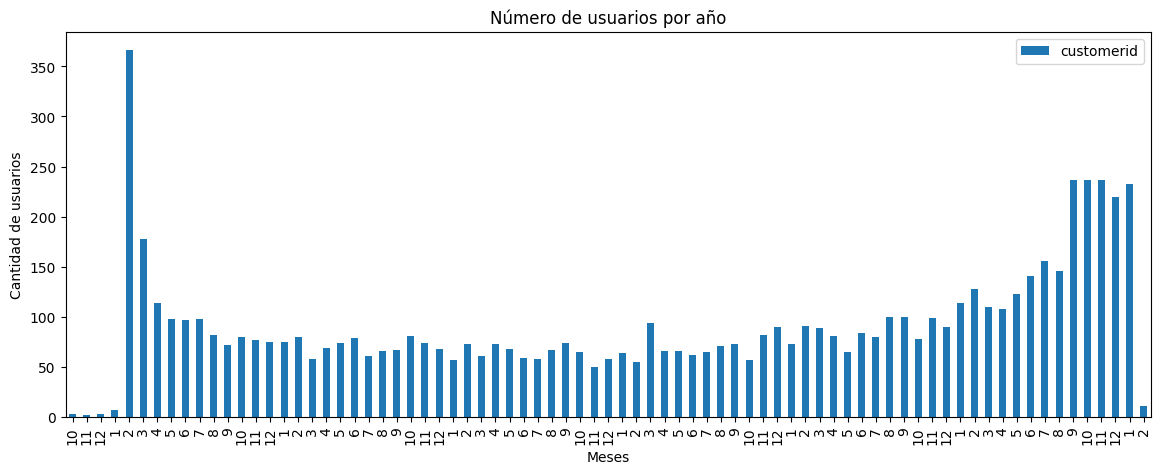

In [10]:
from matplotlib import pyplot as plt
#Obtengo las columnas de año y mes para luego poder graficar el conteo de usuarios
contract['year']= contract['begindate'].dt.year
contract['month']= contract['begindate'].dt.month
user_rate= contract.groupby(['year','month'])['customerid'].count()
user_rate= user_rate.reset_index()

print(user_rate.head(5))
print(user_rate.dtypes)
user_rate.plot(kind='bar',title='Número de usuarios por año',x='month',y='customerid',xlabel='Meses',ylabel='Cantidad de usuarios',figsize=[14,5])
plt.show()

Al observar la gráfica se puede ver que cuando recién empezó la empresa tuvieron muy pocos inicios de contrato, pero que estos se dispararon para inicios del 2014, llegando a los ~350, de ahí volviendo a bajar de golpe al siguiente mes. Desde entonces ha tenido un flujo medianamente constante a lo largo de los meses y años, nomás experimentando una subida considerable para finales del 2019. Lo cuál también es extraño dado que igual se comprobó que en ese tiempo fue que más usuarios salieron de forma continua. Esto puede confirmar el que la empresa debió hacer cambios en su servicio durante esos meses para que afectara la tasa de entrada y salida de clientes.

In [11]:
#Obtengo la lista de IDs de las personas que finalizaron el servicio
gone_users= contract[contract['enddate']!='No']['customerid']
print(gone_users.shape)
print(gone_users.head(5))

(1869,)
,2     3668-QPYBK
,4     9237-HQITU
,5     9305-CDSKC
,8     7892-POOKP
,13    0280-XJGEX
,Name: customerid, dtype: object


In [12]:
#Hago un conteo de las personas que cancelaron que tienen o no el servicio de internet y teléfono
inter_count= internet['customerID'].isin(gone_users)
phone_count= phone['customerID'].isin(gone_users)
print(inter_count.sum())
print(phone_count.sum())

1756
,1699


Teniendo en cuenta que el total de personas que abandonaron la empresa es de 1869, se puede observar que la mayoría de estos contaban con ambos servicios contratados. De aquí se puede concluir que no hay una relación significativa entre abandonar el contrato y tener uno u otro servicio.

In [13]:
#Obtengo la columna objetivo churn a través de enddate
cancelados= []
for date in contract['enddate']:
    if date!='No':
        cancelados.append(1)
    else:
        cancelados.append(0)
contract['churn']= cancelados
print(contract.sample(6))

      customerid  begindate              enddate            type  \
,1576  0993-OSGPT 2014-06-01                   No        One year   
,4485  7975-JMZNT 2014-08-01                   No        Two year   
,2683  8128-YVJRG 2019-05-01  2019-12-01 00:00:00  Month-to-month   
,4070  0531-ZZJWQ 2015-07-01                   No  Month-to-month   
,1070  6166-ILMNY 2019-10-01  2019-12-01 00:00:00  Month-to-month   
,4445  3134-DSHVC 2014-11-01                   No        Two year   
,
,     paperlessbilling              paymentmethod  monthlycharges totalcharges  \
,1576              Yes  Bank transfer (automatic)           60.65       3975.9   
,4485               No  Bank transfer (automatic)           91.70       6075.9   
,2683              Yes               Mailed check           79.65        604.7   
,4070              Yes           Electronic check           74.00       4052.4   
,1070               No  Bank transfer (automatic)           69.75       144.55   
,4445               No  

In [14]:
#Ya con el objetivo obtenido, reemplazo los No con la última fecha del conjunto
contract['enddate']=contract['enddate'].where(contract['enddate']!='No','2020-02-01 00:00:00')
print(contract[contract['enddate']=='No'].count())
#Transformo enddate a formato fecha
contract['enddate']= pd.to_datetime(contract['enddate'],format='%Y-%m-%d')
print(contract.dtypes)

customerid          0
,begindate           0
,enddate             0
,type                0
,paperlessbilling    0
,paymentmethod       0
,monthlycharges      0
,totalcharges        0
,year                0
,month               0
,churn               0
,dtype: int64
,customerid                  object
,begindate           datetime64[ns]
,enddate             datetime64[ns]
,type                        object
,paperlessbilling            object
,paymentmethod               object
,monthlycharges             float64
,totalcharges                object
,year                         int64
,month                        int64
,churn                        int64
,dtype: object


In [15]:
#Ahora hago una resta de las fechas para obtener la duración del contrato
contract['duration']=(contract['enddate']-contract['begindate']).dt.days//30
print(contract.sample(5))

      customerid  begindate    enddate            type paperlessbilling  \
,1858  7517-SAWMO 2018-05-01 2019-12-01  Month-to-month              Yes   
,6750  2144-ESWKO 2016-07-01 2020-02-01        One year              Yes   
,3929  9702-AIUJO 2015-12-01 2020-02-01        One year              Yes   
,2090  6661-EIPZC 2016-02-01 2020-02-01  Month-to-month              Yes   
,3743  2391-SOORI 2019-09-01 2020-01-01  Month-to-month               No   
,
,                  paymentmethod  monthlycharges totalcharges  year  month  \
,1858           Electronic check           73.20       1441.1  2018      5   
,6750    Credit card (automatic)           35.20       1463.7  2016      7   
,3929  Bank transfer (automatic)           44.80      2230.85  2015     12   
,2090    Credit card (automatic)           29.50      1423.05  2016      2   
,3743           Electronic check           49.35       219.65  2019      9   
,
,      churn  duration  
,1858      1        19  
,6750      0        43 

In [16]:
#Compruebo los valores únicos de columnas con más de dos categorías
print(contract['type'].unique())
print(contract['paymentmethod'].unique())

['Month-to-month' 'One year' 'Two year']
,['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
, 'Credit card (automatic)']


In [17]:
personal.columns= [column.lower() for column in personal.columns]
#Combino los primeros dos conjuntos
data= contract.merge(personal,on='customerid')
print(data.head(3))
print(data.shape)

   customerid  begindate    enddate            type paperlessbilling  \
,0  7590-VHVEG 2020-01-01 2020-02-01  Month-to-month              Yes   
,1  5575-GNVDE 2017-04-01 2020-02-01        One year               No   
,2  3668-QPYBK 2019-10-01 2019-12-01  Month-to-month              Yes   
,
,      paymentmethod  monthlycharges totalcharges  year  month  churn  \
,0  Electronic check           29.85        29.85  2020      1      0   
,1      Mailed check           56.95       1889.5  2017      4      0   
,2      Mailed check           53.85       108.15  2019     10      1   
,
,   duration  gender  seniorcitizen partner dependents  
,0         1  Female              0     Yes         No  
,1        34    Male              0      No         No  
,2         2    Male              0      No         No  
,(7043, 16)


In [18]:
internet.columns= [column.lower() for column in internet.columns]
internet['internetservice'].unique()

array(['DSL', 'Fiber optic'], dtype=object)

In [19]:
#Combino con el conjunto de internet
data= data.merge(internet,on='customerid',how='outer')
print(data.sample(5))
print(data.shape)

      customerid  begindate    enddate            type paperlessbilling  \
,5782  4871-JTKJF 2019-11-01 2019-12-01  Month-to-month              Yes   
,2916  4139-JPIAM 2015-11-01 2020-02-01  Month-to-month              Yes   
,2614  3351-NQLDI 2014-03-01 2019-10-01        One year              Yes   
,4873  2320-YKQBO 2019-07-01 2020-02-01  Month-to-month               No   
,3928  4647-MUZON 2018-08-01 2020-02-01  Month-to-month              Yes   
,
,                paymentmethod  monthlycharges totalcharges  year  month  ...  \
,5782         Electronic check           69.65        69.65  2019     11  ...   
,2916  Credit card (automatic)           44.45      2181.55  2015     11  ...   
,2614  Credit card (automatic)           94.35      6341.45  2014      3  ...   
,4873             Mailed check           19.30       144.95  2019      7  ...   
,3928  Credit card (automatic)           95.95       1745.5  2018      8  ...   
,
,      seniorcitizen  partner dependents  internetservi

In [20]:
phone.columns= [column.lower() for column in phone.columns]
#Combino con el conjunto de telefono
data= data.merge(phone,on='customerid',how='outer')
print(data.sample(5))
print(data.shape)

      customerid  begindate    enddate      type paperlessbilling  \
,6472  1150-FTQGN 2015-02-01 2020-02-01  One year               No   
,1514  5799-JRCZO 2014-11-01 2020-02-01  Two year               No   
,1991  0607-MVMGC 2016-05-01 2020-02-01  One year               No   
,1396  9518-RWHZL 2014-07-01 2019-11-01  One year              Yes   
,3521  2550-AEVRU 2015-05-01 2020-02-01  One year               No   
,
,                  paymentmethod  monthlycharges totalcharges  year  month  \
,6472  Bank transfer (automatic)           94.15       5811.8  2015      2   
,1514    Credit card (automatic)           19.50       1215.1  2014     11   
,1991    Credit card (automatic)           78.75      3600.65  2016      5   
,1396    Credit card (automatic)          100.05       6254.2  2014      7   
,3521           Electronic check           53.45         3053  2015      5   
,
,      ...  partner  dependents internetservice  onlinesecurity onlinebackup  \
,6472  ...      Yes         Y

In [21]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
,Int64Index: 7043 entries, 0 to 7042
,Data columns (total 24 columns):
, #   Column            Non-Null Count  Dtype         
,---  ------            --------------  -----         
, 0   customerid        7043 non-null   object        
, 1   begindate         7043 non-null   datetime64[ns]
, 2   enddate           7043 non-null   datetime64[ns]
, 3   type              7043 non-null   object        
, 4   paperlessbilling  7043 non-null   object        
, 5   paymentmethod     7043 non-null   object        
, 6   monthlycharges    7043 non-null   float64       
, 7   totalcharges      7043 non-null   object        
, 8   year              7043 non-null   int64         
, 9   month             7043 non-null   int64         
, 10  churn             7043 non-null   int64         
, 11  duration          7043 non-null   int64         
, 12  gender            7043 non-null   object        
, 13  seniorcitizen     7043 non-null   int64         
, 14  partn

### 2. Preprocesamiento e Ingeniería de Características
*Procesar valores nulos, creación de la variable objetivo, codificación de variables categóricas (justifica tu elección de método).*


In [22]:
#Separo los nombres de todas las columnas que generaron valores Nan
names_nan= ['internetservice','onlinesecurity','onlinebackup','deviceprotection',
            'techsupport','streamingtv','streamingmovies','multiplelines']
#Ya que todas estas son de Yes y No, es lógico llenar los Nan con No
for column in names_nan:
    data[column].fillna('No',inplace=True)
print(data.info())

<class 'pandas.core.frame.DataFrame'>
,Int64Index: 7043 entries, 0 to 7042
,Data columns (total 24 columns):
, #   Column            Non-Null Count  Dtype         
,---  ------            --------------  -----         
, 0   customerid        7043 non-null   object        
, 1   begindate         7043 non-null   datetime64[ns]
, 2   enddate           7043 non-null   datetime64[ns]
, 3   type              7043 non-null   object        
, 4   paperlessbilling  7043 non-null   object        
, 5   paymentmethod     7043 non-null   object        
, 6   monthlycharges    7043 non-null   float64       
, 7   totalcharges      7043 non-null   object        
, 8   year              7043 non-null   int64         
, 9   month             7043 non-null   int64         
, 10  churn             7043 non-null   int64         
, 11  duration          7043 non-null   int64         
, 12  gender            7043 non-null   object        
, 13  seniorcitizen     7043 non-null   int64         
, 14  partn

In [23]:
#Para transformar la columna de totalcharges a float, noté que hubo personas con celdas vacías
#Ubico el índice de todas las personas sin totalcharges en el conjunto original
empty=data[data['totalcharges']==' '].index
print(empty)
print(data.loc[empty])

Int64Index([488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754], dtype='int64')
,      customerid  begindate    enddate      type paperlessbilling  \
,488   4472-LVYGI 2020-02-01 2020-02-01  Two year              Yes   
,753   3115-CZMZD 2020-02-01 2020-02-01  Two year               No   
,936   5709-LVOEQ 2020-02-01 2020-02-01  Two year               No   
,1082  4367-NUYAO 2020-02-01 2020-02-01  Two year               No   
,1340  1371-DWPAZ 2020-02-01 2020-02-01  Two year               No   
,3331  7644-OMVMY 2020-02-01 2020-02-01  Two year               No   
,3826  3213-VVOLG 2020-02-01 2020-02-01  Two year               No   
,4380  2520-SGTTA 2020-02-01 2020-02-01  Two year               No   
,5218  2923-ARZLG 2020-02-01 2020-02-01  One year              Yes   
,6670  4075-WKNIU 2020-02-01 2020-02-01  Two year               No   
,6754  2775-SEFEE 2020-02-01 2020-02-01  Two year              Yes   
,
,                  paymentmethod  monthlycharges totalcharges  year

Como había comprobado antes las fechas de todo el conjunto de datos, se puede observar que estas personas entraron al servicio justo al último mes, por lo que su celda de totalcharges está vacía. Lo más sencillo es rellenar estas celdas vacías con el mismo valor de monthlycharges.

In [24]:
#Reemplazo los valores vacíos
for number in empty:
    data.loc[number,'totalcharges']= data.loc[number,'monthlycharges']
#Compruebo el cambio
print(data.loc[empty])

      customerid  begindate    enddate      type paperlessbilling  \
,488   4472-LVYGI 2020-02-01 2020-02-01  Two year              Yes   
,753   3115-CZMZD 2020-02-01 2020-02-01  Two year               No   
,936   5709-LVOEQ 2020-02-01 2020-02-01  Two year               No   
,1082  4367-NUYAO 2020-02-01 2020-02-01  Two year               No   
,1340  1371-DWPAZ 2020-02-01 2020-02-01  Two year               No   
,3331  7644-OMVMY 2020-02-01 2020-02-01  Two year               No   
,3826  3213-VVOLG 2020-02-01 2020-02-01  Two year               No   
,4380  2520-SGTTA 2020-02-01 2020-02-01  Two year               No   
,5218  2923-ARZLG 2020-02-01 2020-02-01  One year              Yes   
,6670  4075-WKNIU 2020-02-01 2020-02-01  Two year               No   
,6754  2775-SEFEE 2020-02-01 2020-02-01  Two year              Yes   
,
,                  paymentmethod  monthlycharges totalcharges  year  month  \
,488   Bank transfer (automatic)           52.55        52.55  2020      2   
,75

In [25]:
p_data= data.copy()
#Modifico manualmente los valores porque si bien es una variable nominal, 
#necesito que el modelo entienda que el cero es ausencia de valor
inter_values= {'No':0,'DSL':1, 'Fiber optic':2}
p_data['internetservice']=p_data['internetservice'].map(inter_values)
print(p_data['internetservice'].sample(4))

4151    1
,2347    0
,1697    1
,4673    2
,Name: internetservice, dtype: int64


In [26]:
#Me deshago de las características que no me servirán para el entrenamiento
p_data= p_data.drop(['customerid','begindate','enddate','year','month'],axis=1)

In [27]:
#Transformo totalcharges a números
p_data['totalcharges']=pd.to_numeric(p_data['totalcharges'])
print(p_data.info())
print(p_data.sample(5))

<class 'pandas.core.frame.DataFrame'>
,Int64Index: 7043 entries, 0 to 7042
,Data columns (total 19 columns):
, #   Column            Non-Null Count  Dtype  
,---  ------            --------------  -----  
, 0   type              7043 non-null   object 
, 1   paperlessbilling  7043 non-null   object 
, 2   paymentmethod     7043 non-null   object 
, 3   monthlycharges    7043 non-null   float64
, 4   totalcharges      7043 non-null   float64
, 5   churn             7043 non-null   int64  
, 6   duration          7043 non-null   int64  
, 7   gender            7043 non-null   object 
, 8   seniorcitizen     7043 non-null   int64  
, 9   partner           7043 non-null   object 
, 10  dependents        7043 non-null   object 
, 11  internetservice   7043 non-null   int64  
, 12  onlinesecurity    7043 non-null   object 
, 13  onlinebackup      7043 non-null   object 
, 14  deviceprotection  7043 non-null   object 
, 15  techsupport       7043 non-null   object 
, 16  streamingtv       704

In [28]:
#Obtengo una lista de los nombres de columnas categoricas para poder usar OrdinalEncoder despues
objects= []
for column in p_data.columns:
    if p_data[column].dtype == object:
        objects.append(column)
print(objects)

['type', 'paperlessbilling', 'paymentmethod', 'gender', 'partner', 'dependents', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'multiplelines']


In [29]:
#Aquí codifico todas las columnas con datos de Yes y No para transformarlos a 1 y 0
from sklearn.preprocessing import OrdinalEncoder
encoder= OrdinalEncoder()
t_data= pd.DataFrame(encoder.fit_transform(p_data[objects]),columns=objects)
print(t_data.sample(3))
print(t_data.info())

      type  paperlessbilling  paymentmethod  gender  partner  dependents  \
,268    2.0               0.0            3.0     1.0      0.0         0.0   
,4739   0.0               1.0            0.0     0.0      0.0         0.0   
,2857   2.0               0.0            0.0     0.0      1.0         1.0   
,
,      onlinesecurity  onlinebackup  deviceprotection  techsupport  \
,268              0.0           0.0               0.0          0.0   
,4739             1.0           0.0               0.0          0.0   
,2857             0.0           1.0               0.0          1.0   
,
,      streamingtv  streamingmovies  multiplelines  
,268           0.0              0.0            0.0  
,4739          0.0              0.0            1.0  
,2857          0.0              1.0            0.0  
,<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 7043 entries, 0 to 7042
,Data columns (total 13 columns):
, #   Column            Non-Null Count  Dtype  
,---  ------            -------------- 

In [30]:
#Obtengo una lista de los nombres de columnas númericas para poder usar StandardScaler despues
numbers= ['monthlycharges', 'totalcharges','duration']
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
scaled_data= pd.DataFrame(scaler.fit_transform(p_data[numbers]),columns=numbers)
print(scaled_data.sample(5))

      monthlycharges  totalcharges  duration
,3723       -1.472741     -0.848330 -0.585768
,3321       -1.303237     -0.249209  1.270539
,5611        1.184473      1.530949  1.028412
,6760       -0.510560     -0.924480 -1.150730
,2498       -0.364322     -0.392641 -0.222577


In [31]:
#Combino todos los datos en un solo conjunto
recover= p_data[['seniorcitizen','internetservice','churn']]
t_data=pd.concat([t_data,scaled_data],axis=1)
t_data= pd.concat([t_data,recover],axis=1)
print(t_data.info())
print(t_data.sample(5))

<class 'pandas.core.frame.DataFrame'>
,RangeIndex: 7043 entries, 0 to 7042
,Data columns (total 19 columns):
, #   Column            Non-Null Count  Dtype  
,---  ------            --------------  -----  
, 0   type              7043 non-null   float64
, 1   paperlessbilling  7043 non-null   float64
, 2   paymentmethod     7043 non-null   float64
, 3   gender            7043 non-null   float64
, 4   partner           7043 non-null   float64
, 5   dependents        7043 non-null   float64
, 6   onlinesecurity    7043 non-null   float64
, 7   onlinebackup      7043 non-null   float64
, 8   deviceprotection  7043 non-null   float64
, 9   techsupport       7043 non-null   float64
, 10  streamingtv       7043 non-null   float64
, 11  streamingmovies   7043 non-null   float64
, 12  multiplelines     7043 non-null   float64
, 13  monthlycharges    7043 non-null   float64
, 14  totalcharges      7043 non-null   float64
, 15  duration          7043 non-null   float64
, 16  seniorcitizen     704

### 3. Selección de Variables y Entrenamiento de Modelos (Baseline)
*Entrena al menos dos modelos distintos sin aplicar técnicas de balanceo de clases. Evalúa su AUC-ROC y Recall.*


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score

import lightgbm as lgb
import xgboost as xgb

In [33]:
#Separo el objetivo y las características, y entrenamiento y testeo
target= t_data['churn']
features= t_data.drop('churn',axis=1)
features_train, features_test, target_train, target_test= train_test_split(features,target,test_size=0.25,random_state=1234)
print(features_train.shape)
print(target_train.shape)
print(features_test.shape)
print(target_test.shape)

(5282, 18)
,(5282,)
,(1761, 18)
,(1761,)


In [34]:
#Defino los parámetros de LGB para entrenarlo
d_train= lgb.Dataset(features_train, label=target_train)
lgbm_params={'learning_rate':0.05,'boosting_type':'gbdt','objective':'binary',
 'num_leaves':120,'max_depth':8}
model_lgb= lgb.train(lgbm_params,d_train,50)

[LightGBM] [Info] Number of positive: 1412, number of negative: 3870
,[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000699 seconds.
,You can set `force_row_wise=true` to remove the overhead.
,And if memory is not enough, you can set `force_col_wise=true`.
,[LightGBM] [Info] Total Bins 619
,[LightGBM] [Info] Number of data points in the train set: 5282, number of used features: 18
,[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.267323 -> initscore=-1.008247
,[LightGBM] [Info] Start training from score -1.008247
,[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
,[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
,[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
,[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
,[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
,[LightGBM] [Warning] No further splits with positive ga

In [35]:
#Uso el modelo LightGBM y lo evaluo
probs_lgb= model_lgb.predict(features_test)
prediclgb=[]
for prob in probs_lgb:
    if prob >= 0.5:
        prediclgb.append(1)
    else:
        prediclgb.append(0)
recall_lgb= recall_score(target_test,prediclgb)
auc_lgb= roc_auc_score(target_test,probs_lgb)
print('El valor recall de LightGBM es:',recall_lgb)
print('El valor auc_roc de LightGBM es:',auc_lgb)

El valor recall de LightGBM es: 0.48358862144420134
,El valor auc_roc de LightGBM es: 0.8158955444281859


In [36]:
#Fijo los parámetros del modelo de XGBoost
d_trainx=xgb.DMatrix(features_train, label=target_train)
xgb_params= {'booster':'gbtree','eta':0.05,'max_depth':13}
model_xg= xgb.train(xgb_params,d_trainx,num_boost_round=50)
#Uso el modelo XGBoost y lo evaluo
d_testx= xgb.DMatrix(features_test)
probs_xgb= model_xg.predict(d_testx)
pred_xgb=[]
for prob in probs_xgb:
    if prob >= 0.5:
        pred_xgb.append(1)
    else:
        pred_xgb.append(0)
recall_xgb= recall_score(target_test,pred_xgb)
auc_xgb= roc_auc_score(target_test,probs_xgb)
print('El valor recall de LightGBM es:',recall_xgb)
print('El valor auc_roc de LightGBM es:',auc_xgb)

El valor recall de LightGBM es: 0.5032822757111597
,El valor auc_roc de LightGBM es: 0.7707357264635998


### 4. Optimización y Manejo de Desbalance
*Aplica al menos una técnica para manejar el desbalance de clases (upsampling, downsampling, o ajuste de pesos) y busca los mejores hiperparámetros. Evalúa nuevamente.*

In [37]:
from sklearn.utils import shuffle

In [38]:
#Creo la función de upsampling para incrementar las observaciones de valor 1
def upsample (features,target,repeat):
    f_0= features[target==0]
    t_0= target[target==0]
    f_1= features[target==1]
    t_1= target[target==1]

    feat_up= pd.concat([f_0]+[f_1]*repeat)
    targ_up= pd.concat([t_0]+[t_1]*repeat)

    new_feats, new_target= shuffle(feat_up,targ_up,random_state=12345)

    return new_feats, new_target

In [39]:
positive_count= target_train[target_train==1].count()
negative_count= target_train[target_train==0].count()
print(positive_count)
print(negative_count)

1412
,3870


In [40]:
#Creo nuevos conjuntos de datos para la segunda prueba de modelos
new_feats, new_target= upsample(features_train, target_train, 2)
print(new_feats.shape)
print(new_target.shape)

(6694, 18)
,(6694,)


In [41]:
#Defino los parámetros de LGB para entrenarlo
d_train2= lgb.Dataset(new_feats, label=new_target)
lgbm_params={'learning_rate':0.04,'boosting_type':'gbdt','objective':'binary',
 'num_leaves':50,'max_depth':7,'verbosity':0}
lgb2= lgb.train(lgbm_params,d_train2,60)
#Uso el modelo LightGBM y lo evaluo
probs_lgb2= lgb2.predict(features_test)
prediclgb2=[]
for prob in probs_lgb2:
    if prob >= 0.5:
        prediclgb2.append(1)
    else:
        prediclgb2.append(0)
recall_lgb2= recall_score(target_test,prediclgb2)
auc_lgb2= roc_auc_score(target_test,probs_lgb2)
print('El valor recall de LightGBM es:',recall_lgb2)
print('El valor auc_roc de LightGBM es:',auc_lgb2)

[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000492 seconds.
,You can set `force_row_wise=true` to remove the overhead.
,And if memory is not enough, you can set `force_col_wise=true`.
,El valor recall de LightGBM es: 0.6608315098468271
,El valor auc_roc de LightGBM es: 0.822642164825281


In [ ]:
#Fijo los parámetros del modelo de XGBoost
d_trainx2=xgb.DMatrix(new_feats, label=new_target)
xgb_params= {'booster':'gbtree','eta':0.05,'max_depth':7,'subsample':0.4,'min_child_weight':70,'tree_method':'exact'}
model_xg2= xgb.train(xgb_params,d_trainx2,num_boost_round=80)
#Uso el modelo XGBoost y lo evaluo
d_testx2= xgb.DMatrix(features_test)
probs_xgb2= model_xg2.predict(d_testx2)
pred_xgb2=[]
for prob in probs_xgb2:
    if prob >= 0.5:
        pred_xgb2.append(1)
    else:
        pred_xgb2.append(0)
recall_xgb2= recall_score(target_test,pred_xgb2)
auc_xgb2= roc_auc_score(target_test,probs_xgb2)
print('El valor recall de LightGBM es:',recall_xgb2)
print('El valor auc_roc de LightGBM es:',auc_xgb2)

## Etapa 3: Informe de Solución
*Escribe aquí tu informe final para el equipo de negocio. Asegúrate de responder:*
1. *¿Qué modelo elegiste finalmente y por qué?*
   
   El modelo final elegido es el segundo de LightGBM con la estrategia de upsampling aplicada, ya que se obtuvo los más altos valores de precisión en las predicciones otorgadas, lo cual significa que es muy bueno distinguiendo aquellos clientes que pueden abandonar el servicio de los que no, por lo que la estrategia de marketing de actuar sobre esos posibles desertores será muy efectiva.
   
3. *¿Cuáles fueron las métricas finales (AUC-ROC y Recall) en el conjunto de prueba?*
   
   Recall (0.71) y Auc-roc (0.83)

   
5. *En términos de negocio: ¿Qué significa tu valor de Recall? ¿Cómo impactaría tu modelo en la retención de clientes si el equipo de marketing lo utiliza hoy?*

  De cada 100 clientes, el modelo atraparía alrededor de 70 que efectivamente se irían, por lo que el equipo de marketing puede aplicar sus estrategias de retención de forma temprana y oportuna para aumentar significativamente las probabilidades de que la empresa no los pierda. 